In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score
)

tf.random.set_seed(42)
np.random.seed(42)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [2]:
df = pd.read_csv("../data/student-por.csv", sep=";")

# Create target categories
grade_bins = [0, 10, 14, 17, 21]

grade_labels = [
    "Poor",
    "Average",
    "Good",
    "Excellent"
]

df["Performance"] = pd.cut(
    df["G3"],
    bins=grade_bins,
    labels=grade_labels,
    right=False
)

# Separate features and target
X = df.drop(columns=["G3", "Performance"])
y = df["Performance"]

In [3]:
X_early = X.drop(columns=["G1", "G2"])
X_late = X.copy()

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X_early,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (454, 30)
Validation: (97, 30)
Testing: (98, 30)


In [6]:
X_train_late = X_late.loc[X_train.index]
X_val_late = X_late.loc[X_val.index]
X_test_late = X_late.loc[X_test.index]

In [7]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

def preprocess_data(X_train, X_val, X_test):

    categorical = X_train.select_dtypes(
        include=["object"]
    ).columns.tolist()

    numerical = X_train.select_dtypes(
        include=["number"]
    ).columns.tolist()

    preprocessor = ColumnTransformer([
        ("num", StandardScaler(), numerical),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical)
    ])

    X_train_processed = preprocessor.fit_transform(X_train)
    X_val_processed = preprocessor.transform(X_val)
    X_test_processed = preprocessor.transform(X_test)

    return X_train_processed, X_val_processed, X_test_processed

In [8]:
# Early prediction
X_train_early, X_val_early, X_test_early = preprocess_data(
    X_train, X_val, X_test
)

# Late prediction
X_train_late, X_val_late, X_test_late = preprocess_data(
    X_train_late, X_val_late, X_test_late
)

print("Early feature count:", X_train_early.shape[1])
print("Late feature count:", X_train_late.shape[1])

Early feature count: 56
Late feature count: 58


C:\Users\Parv\AppData\Local\Temp\ipykernel_12472\2122530982.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = X_train.select_dtypes(
C:\Users\Parv\AppData\Local\Temp\ipykernel_12472\2122530982.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-

In [9]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)

y_val_encoded = label_encoder.transform(y_val)

y_test_encoded = label_encoder.transform(y_test)

print("Class mapping:")

for i, category in enumerate(label_encoder.classes_):
    print(category, ":", i)

Class mapping:
Average : 0
Excellent : 1
Good : 2
Poor : 3


In [10]:
if hasattr(X_train_early, "toarray"):
    X_train_early = X_train_early.toarray()
    X_val_early = X_val_early.toarray()
    X_test_early = X_test_early.toarray()

if hasattr(X_train_late, "toarray"):
    X_train_late = X_train_late.toarray()
    X_val_late = X_val_late.toarray()
    X_test_late = X_test_late.toarray()

In [11]:
y_train_encoded = np.array(y_train_encoded)
y_val_encoded = np.array(y_val_encoded)
y_test_encoded = np.array(y_test_encoded)

In [12]:
print("Training shape:", X_train_early.shape)
print("Validation shape:", X_val_early.shape)
print("Testing shape:", X_test_early.shape)

print("Number of classes:", len(np.unique(y_train_encoded)))

Training shape: (454, 56)
Validation shape: (97, 56)
Testing shape: (98, 56)
Number of classes: 4


In [13]:
def build_dnn(input_features):

    model = keras.Sequential([
        layers.Input(shape=(input_features,)),

        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),

        layers.Dense(32, activation="relu"),
        layers.Dropout(0.2),

        layers.Dense(4, activation="softmax")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [14]:
model_early = build_dnn(
    X_train_early.shape[1]
)

model_early.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         3,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,860 (22.89 KB)

 Trainable params: 5,860 (22.89 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_early = model_early.fit(
    X_train_early,
    y_train_encoded,
    validation_data=(X_val_early, y_val_encoded),
    epochs=100,
    batch_size=16,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4405 - loss: 1.3170 - val_accuracy: 0.5464 - val_loss: 1.1728
Epoch 2/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5374 - loss: 1.1756 - val_accuracy: 0.5155 - val_loss: 1.1267
Epoch 3/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5507 - loss: 1.1201 - val_accuracy: 0.5464 - val_loss: 1.0972
Epoch 4/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5396 - loss: 1.1061 - val_accuracy: 0.5155 - val_loss: 1.0772
Epoch 5/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5286 - loss: 1.0624 - val_accuracy: 0.5052 - val_loss: 1.0555
Epoch 6/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5683 - loss: 1.0379 - val_accuracy: 0.4845 - val_loss: 1.0419
Epoch 7/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5793 - loss: 1.0113 - val_accuracy: 0.4845 - val_loss: 1.0283
Epoch 8/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5529 - loss: 1.0188 - val_accuracy: 0.5155 - v

In [16]:
y_pred_prob = model_early.predict(X_val_early)

y_pred_dnn = np.argmax(y_pred_prob, axis=1)

print("Accuracy:",
      accuracy_score(y_val_encoded, y_pred_dnn))

print("Macro F1:",
      f1_score(y_val_encoded, y_pred_dnn, average="macro"))

print("\nClassification Report:")

print(
    classification_report(
        y_val_encoded,
        y_pred_dnn,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
Accuracy: 0.5567010309278351
Macro F1: 0.40729343520090544

Classification Report:
              precision    recall  f1-score   support

     Average       0.59      0.79      0.68        53
   Excellent       1.00      0.14      0.25         7
        Good       0.44      0.32      0.37        22
        Poor       0.44      0.27      0.33        15

    accuracy                           0.56        97
   macro avg       0.62      0.38      0.41        97
weighted avg       0.56      0.56      0.52        97



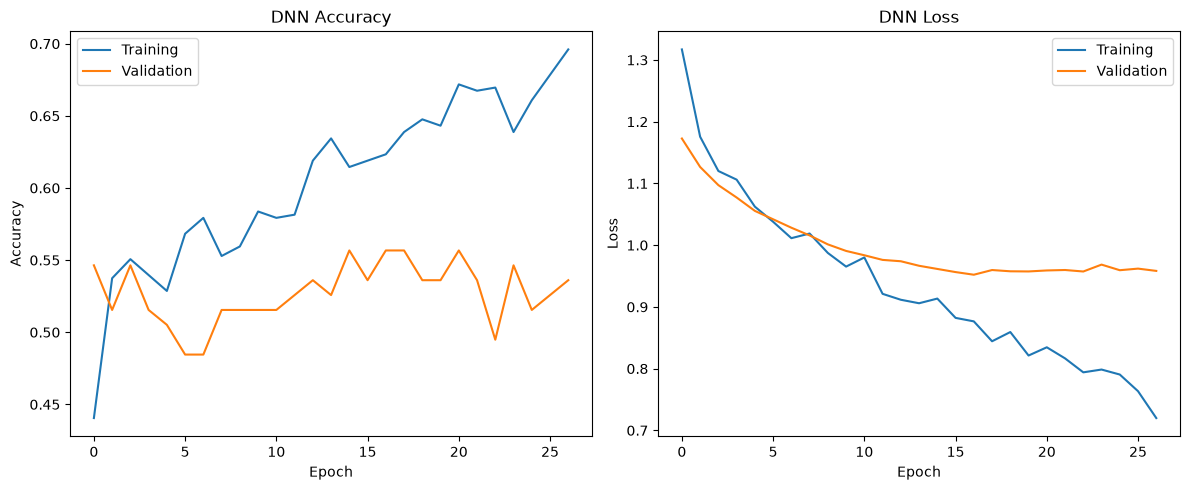

In [19]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(history_early.history["accuracy"], label="Training")
plt.plot(history_early.history["val_accuracy"], label="Validation")

plt.title("DNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(history_early.history["loss"], label="Training")
plt.plot(history_early.history["val_loss"], label="Validation")

plt.title("DNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [20]:
model_late = build_dnn(
    X_train_late.shape[1]
)

model_late.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │         3,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,988 (23.39 KB)

 Trainable params: 5,988 (23.39 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
early_stopping_late = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_late = model_late.fit(
    X_train_late,
    y_train_encoded,
    validation_data=(X_val_late, y_val_encoded),
    epochs=100,
    batch_size=16,
    callbacks=[early_stopping_late],
    verbose=1
)

Epoch 1/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.3789 - loss: 1.3581 - val_accuracy: 0.5567 - val_loss: 1.0788
Epoch 2/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5529 - loss: 1.0453 - val_accuracy: 0.5773 - val_loss: 0.9688
Epoch 3/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6013 - loss: 0.9390 - val_accuracy: 0.5979 - val_loss: 0.8833
Epoch 4/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6652 - loss: 0.8272 - val_accuracy: 0.6186 - val_loss: 0.8076
Epoch 5/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6718 - loss: 0.7860 - val_accuracy: 0.6598 - val_loss: 0.7356
Epoch 6/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6784 - loss: 0.7503 - val_accuracy: 0.7113 - val_loss: 0.6826
Epoch 7/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7247 - loss: 0.6745 - val_accuracy: 0.7320 - val_loss: 0.6451
Epoch 8/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7269 - loss: 0.6452 - val_accuracy: 0.7835 - v

In [22]:
y_pred_prob_late = model_late.predict(X_val_late)

y_pred_late = np.argmax(
    y_pred_prob_late,
    axis=1
)

print("Accuracy:",
      accuracy_score(y_val_encoded, y_pred_late))

print("Macro F1:",
      f1_score(y_val_encoded, y_pred_late, average="macro"))

print("\nClassification Report:")

print(
    classification_report(
        y_val_encoded,
        y_pred_late,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
Accuracy: 0.8350515463917526
Macro F1: 0.7727405561707887

Classification Report:
              precision    recall  f1-score   support

     Average       0.85      0.94      0.89        53
   Excellent       0.80      0.57      0.67         7
        Good       0.81      0.77      0.79        22
        Poor       0.83      0.67      0.74        15

    accuracy                           0.84        97
   macro avg       0.82      0.74      0.77        97
weighted avg       0.83      0.84      0.83        97



In [23]:
dnn_results = pd.DataFrame({
    "Experiment": ["Early DNN", "Late DNN"],

    "Accuracy": [
        accuracy_score(y_val_encoded, y_pred_dnn),
        accuracy_score(y_val_encoded, y_pred_late)
    ],

    "Macro F1": [
        f1_score(y_val_encoded, y_pred_dnn, average="macro"),
        f1_score(y_val_encoded, y_pred_late, average="macro")
    ]
})

dnn_results

,Experiment,Accuracy,Macro F1
0,Early DNN,0.556701,0.407293
1,Late DNN,0.835052,0.772741


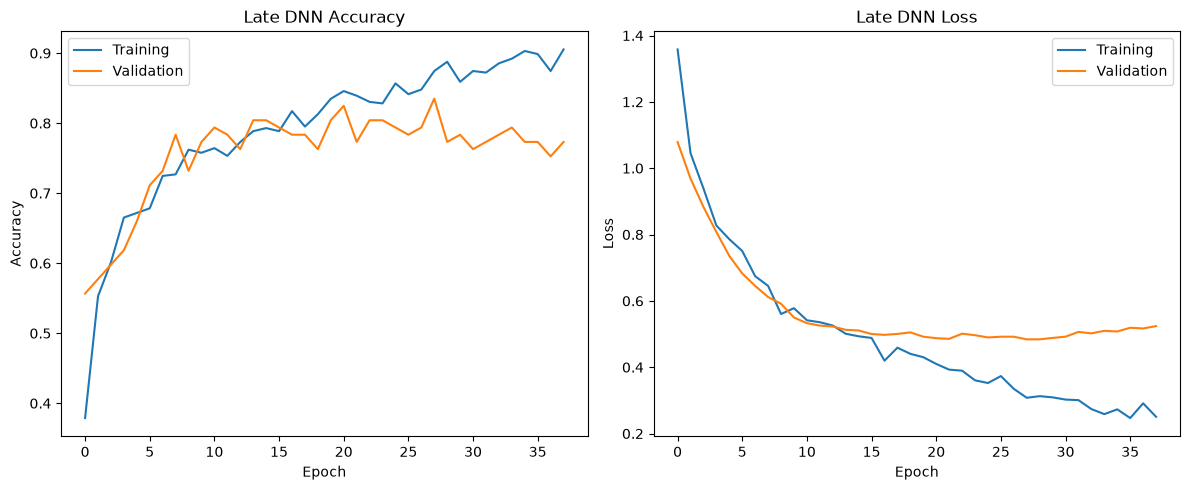

In [24]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(history_late.history["accuracy"], label="Training")
plt.plot(history_late.history["val_accuracy"], label="Validation")

plt.title("Late DNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(history_late.history["loss"], label="Training")
plt.plot(history_late.history["val_loss"], label="Validation")

plt.title("Late DNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [25]:
# Save DNN validation predictions

np.savez(
    "../models/dnn_validation_predictions.npz",
    y_pred_early=y_pred_dnn,
    y_pred_late=y_pred_late
)

print("DNN predictions saved successfully!")

DNN predictions saved successfully!
